# Voces y documentos peruanos · Extracción

**Fecha de extracción: 25 de octubre de 2026, Perú.**

**Fuentes y licencias:** documentos de Wikimedia Commons y de la Biblioteca Nacional del Perú, con dominio público/CC0/CC BY/CC BY-SA según `datos/seleccion_documentos.csv`; audio OpenSLR 73, Google, CC BY-SA 4.0, y dos entrevistas callejeras de Wikimedia Commons, CC BY-SA 4.0. Fuente oficial: https://www.openslr.org/73/. Cada URL, autor, licencia y procedimiento de recuperación está registrado en los manifiestos y `datos/fuentes.csv`.

**Modelos ejecutados:** PaddleOCR 3.7.0, PP-OCRv6 medium, idioma español, CPU, sin clasificación de orientación ni rectificación; faster-whisper 1.2.1 `small`, CPU/int8, beam 5 y VAD. Diarización mediante WeSpeaker y agrupamiento del módulo `voz.py` de la Sesión 13. Las fotos mantienen sombra, perspectiva y reflejos reales. Se normalizó EXIF y se hicieron recortes de páginas distintas, sin degradación sintética.

**Estado:** resultados de extracción reales. Se completaron y confirmaron veinte referencias manuales. La auditoría registra 14/20 JSON correctos. La celda de privacidad muestra el estado vigente; la entrega exige además capturas auténticas y una app pública verificada.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import pandas as pd
from IPython.display import display, Image
import entorno
from pipeline import *
for p in ['paddleocr','paddlepaddle','faster-whisper','pyannote-audio','pandas','plotly']:
    print(p, metadata.version(p))
print('Enunciado: https://github.com/d2cml-ai/Data-Science-Python/issues/190')


paddleocr 3.7.0
paddlepaddle 3.2.2
faster-whisper 1.2.1
pyannote-audio 4.0.7
pandas 2.3.3
plotly 6.3.1
Enunciado: https://github.com/d2cml-ai/Data-Science-Python/issues/190


## Recuperación e inferencia

Los originales se conservan en `datos/raw/` y se excluyen de Git. `python recuperar_documentos.py` reconstruye las 25 imágenes desde sus URLs, páginas y recortes, verificando SHA256. `python generar_audio_openslr.py` reconstruye 20 montajes de locuciones auténticas; las referencias del proveedor se guardan como metadatos privados y no se usan como referencias manuales. `python agregar_entrevistas.py` recupera las dos entrevistas naturales.

Cambiar `RECALCULAR` a `True` solo para volver a ejecutar los motores. La visualización de las salidas guardadas no requiere volver a inferir.

In [2]:
RECALCULAR = False
if RECALCULAR:
    extraer_documentos(forzar=True)
    transcribir_audios(forzar=True)
documentos = leer_csv(DOC_CSV)
audios = leer_csv(AUDIO_CSV)
fuentes = leer_csv(DATOS/'fuentes.csv')
print('Documentos:', documentos.shape, '| Audios:', audios.shape, '| Fuentes:', fuentes.shape)
print('Audio total:', round(pd.to_numeric(audios.duracion_seg).sum()/60, 2), 'minutos')
display(documentos.head(5))
display(audios.head(5))


Documentos: (25, 7) | Audios: (22, 8) | Fuentes: (47, 7)
Audio total: 38.57 minutos


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,https://commons.wikimedia.org/wiki/File:Consti...,"EL LIBERTADOR PERSONA001,\nGRAN MARISCAL DELOS...",PaddleOCR 3.7.0; PP-OCRv6 medium; lang=es; CPU...,"El libertador PERSONA003,\nGran mariscal de lo..."
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,https://commons.wikimedia.org/wiki/File:Consti...,4\nTITULO 2.\nDe la Religion.\nArt4. La Nacion...,PaddleOCR 3.7.0; PP-OCRv6 medium; lang=es; CPU...,
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,https://commons.wikimedia.org/wiki/File:Consti...,-5-\n—10. Es nula y sin efecto cualquiera ley ...,PaddleOCR 3.7.0; PP-OCRv6 medium; lang=es; CPU...,
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,https://commons.wikimedia.org/wiki/File:Consti...,—6\n21. Eh secreto de las cartas es invielable...,PaddleOCR 3.7.0; PP-OCRv6 medium; lang=es; CPU...,21. El secreto de las cartas es inviolable; no...
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,https://commons.wikimedia.org/wiki/File:Consti...,--7--\n—33. Son peruanos por macimiento:\n1. L...,PaddleOCR 3.7.0; PP-OCRv6 medium; lang=es; CPU...,33. Son peruanos por nacimiento:\n1. Los que n...


,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
0,clip_001,datos/raw/audio/clip_001.wav,101.03,es,No me gusta que el departamento esté en planta...,faster-whisper small; CPU; int8; VAD,,no me gusta que el departamento este en planta...
1,clip_002,datos/raw/audio/clip_002.wav,100.19,es,¿Quiere que le proporcione la dirección electr...,faster-whisper small; CPU; int8; VAD,,
2,clip_003,datos/raw/audio/clip_003.wav,96.91,es,El meditar te puede ayudar a ser un poco más p...,faster-whisper small; CPU; int8; VAD,,
3,clip_004,datos/raw/audio/clip_004.wav,100.27,es,Me gustan demasiado las películas de ciencia f...,faster-whisper small; CPU; int8; VAD,,
4,clip_005,datos/raw/audio/clip_005.wav,98.07,es,Un amigo mío está haciendo una exposición sobr...,faster-whisper small; CPU; int8; VAD,,un amigo mio esta haciendo una expoción sobre ...


## Limpieza, duplicados y calidad

Se comprueban los archivos reales por SHA256, textos vacíos y duración medida en el WAV. Un OCR corto no implica automáticamente que el original sea ilegible: los manuscritos se inspeccionaron visualmente. El estudiante debe confirmar la legibilidad de la muestra al transcribirla. Los candidatos iniciales que eran retratos, estampillas o imágenes sin la tipología requerida no forman parte del corpus.

In [3]:
import soundfile as sf
hash_doc = documentos.archivo.map(lambda x: sha256(normalizar_ruta(x)))
hash_audio = audios.archivo_audio.map(lambda x: sha256(normalizar_ruta(x)))
print('Duplicados documentales por hash:', int(hash_doc.duplicated().sum()))
print('Duplicados de audio por hash:', int(hash_audio.duplicated().sum()))
print('Textos OCR vacíos:', int(documentos.texto_ocr.str.strip().eq('').sum()))
print('Transcripciones ASR vacías:', int(audios.texto_asr.str.strip().eq('').sum()))
print('WAV con duración inválida:', sum(sf.info(str(normalizar_ruta(x))).duration <= 0 for x in audios.archivo_audio))
display(leer_csv(DATOS/'descartes.csv'))


Duplicados documentales por hash: 0
Duplicados de audio por hash: 0
Textos OCR vacíos: 0
Transcripciones ASR vacías: 0
WAV con duración inválida: 0


,id,modalidad,archivo,motivo,accion


## Seudonimización y revisión

El pipeline sustituye patrones de DNI de ocho dígitos, correos y teléfonos. Es una primera pasada: no detecta exhaustivamente nombres ni direcciones. La revisión humana se registra por contenido exacto y se invalida cuando cambian OCR, ASR, referencia, predicción alternativa o JSON. Hasta entonces todos los textos son borradores locales. Los originales y la correspondencia sensible permanecen privados.

In [4]:
from validar_publicacion import estado
revision = estado()
print('Revisiones humanas completas:', int(revision.revisado.str.lower().isin(['si','sí']).sum()), '/', len(revision))
print('Sustituciones automáticas adicionales necesarias con las reglas básicas:', sum(seudonimizar_basico(t)[1] for t in documentos.texto_ocr) + sum(seudonimizar_basico(t)[1] for t in audios.texto_asr))
print('El recuento anterior no acredita ausencia de nombres: falta revisión humana de todos los textos.')


Revisiones humanas completas: 47 / 47
Sustituciones automáticas adicionales necesarias con las reglas básicas: 0
El recuento anterior no acredita ausencia de nombres: falta revisión humana de todos los textos.


## Tres gráficos y comprobación de extremos

Los gráficos usan Plotly Express. Los títulos expresan resultados observados y las unidades se mantienen separadas para OCR y ASR. Se adjunta también una imagen estática para la visualización directa en GitHub.

Tres documentos más largos:
     id    tipo    n
doc_004 impreso 1765
doc_008 impreso 1661
doc_007 impreso 1656
Tres documentos más cortos:
     id       tipo   n
doc_011       foto 185
doc_023 manuscrito 320
doc_016       foto 429
Tres clips más largos y cortos:
      id  duracion_seg
clip_022        189.01
clip_021        136.30
clip_017        103.36
      id  duracion_seg
clip_003         96.91
clip_015         97.59
clip_005         98.07
df.shape (25, 7) (22, 8) | primeras cinco filas:
        id                           archivo     tipo  \
0  doc_001  datos/raw/documentos/doc_001.jpg  impreso   
1  doc_002  datos/raw/documentos/doc_002.jpg  impreso   
2  doc_003  datos/raw/documentos/doc_003.jpg  impreso   
3  doc_004  datos/raw/documentos/doc_004.jpg  impreso   
4  doc_005  datos/raw/documentos/doc_005.jpg  impreso   

                                              fuente  \
0  https://commons.wikimedia.org/wiki/File:Consti...   
1  https://commons.wikimedia.org/wiki/File:Const

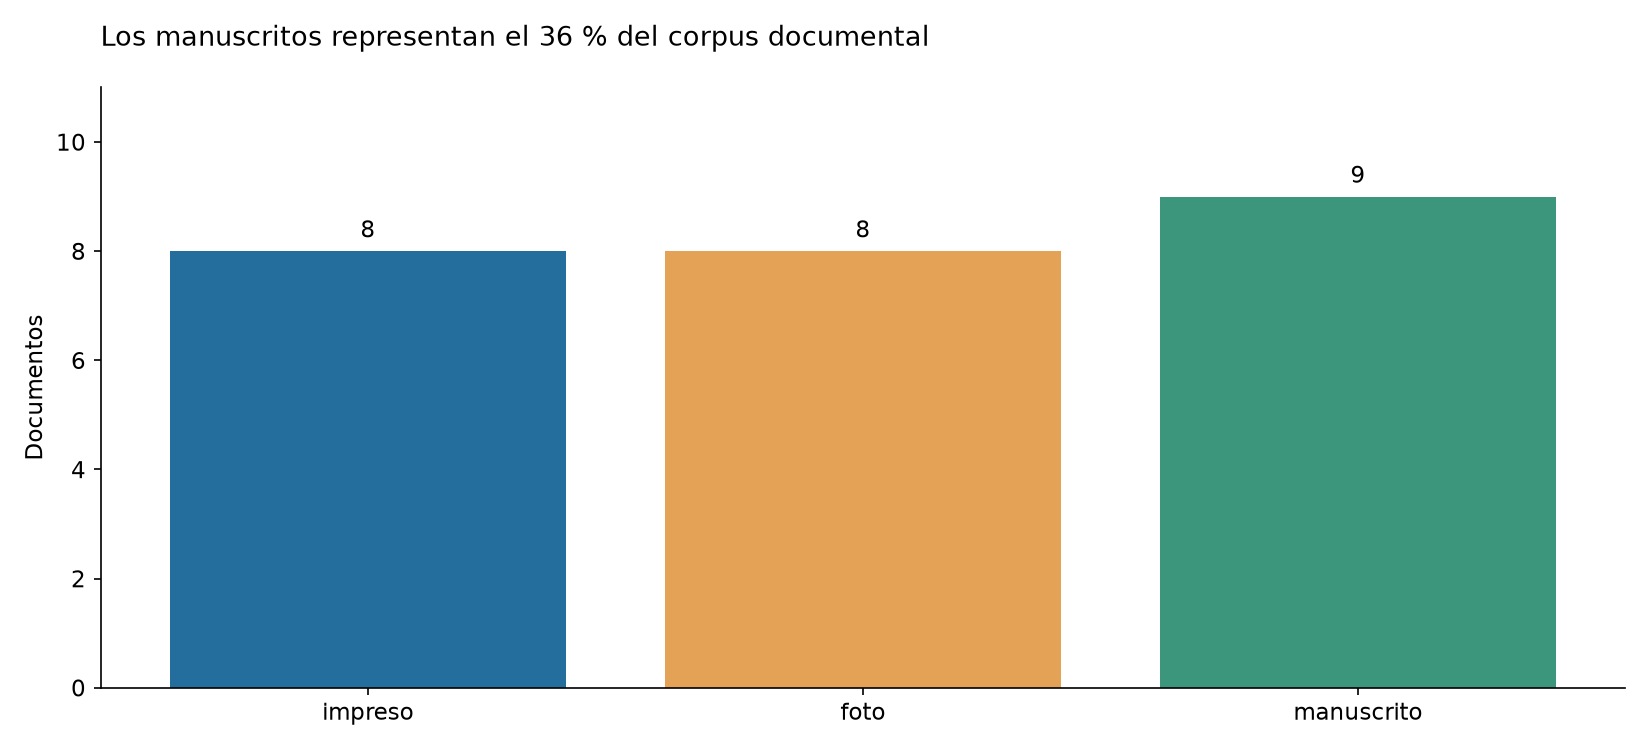

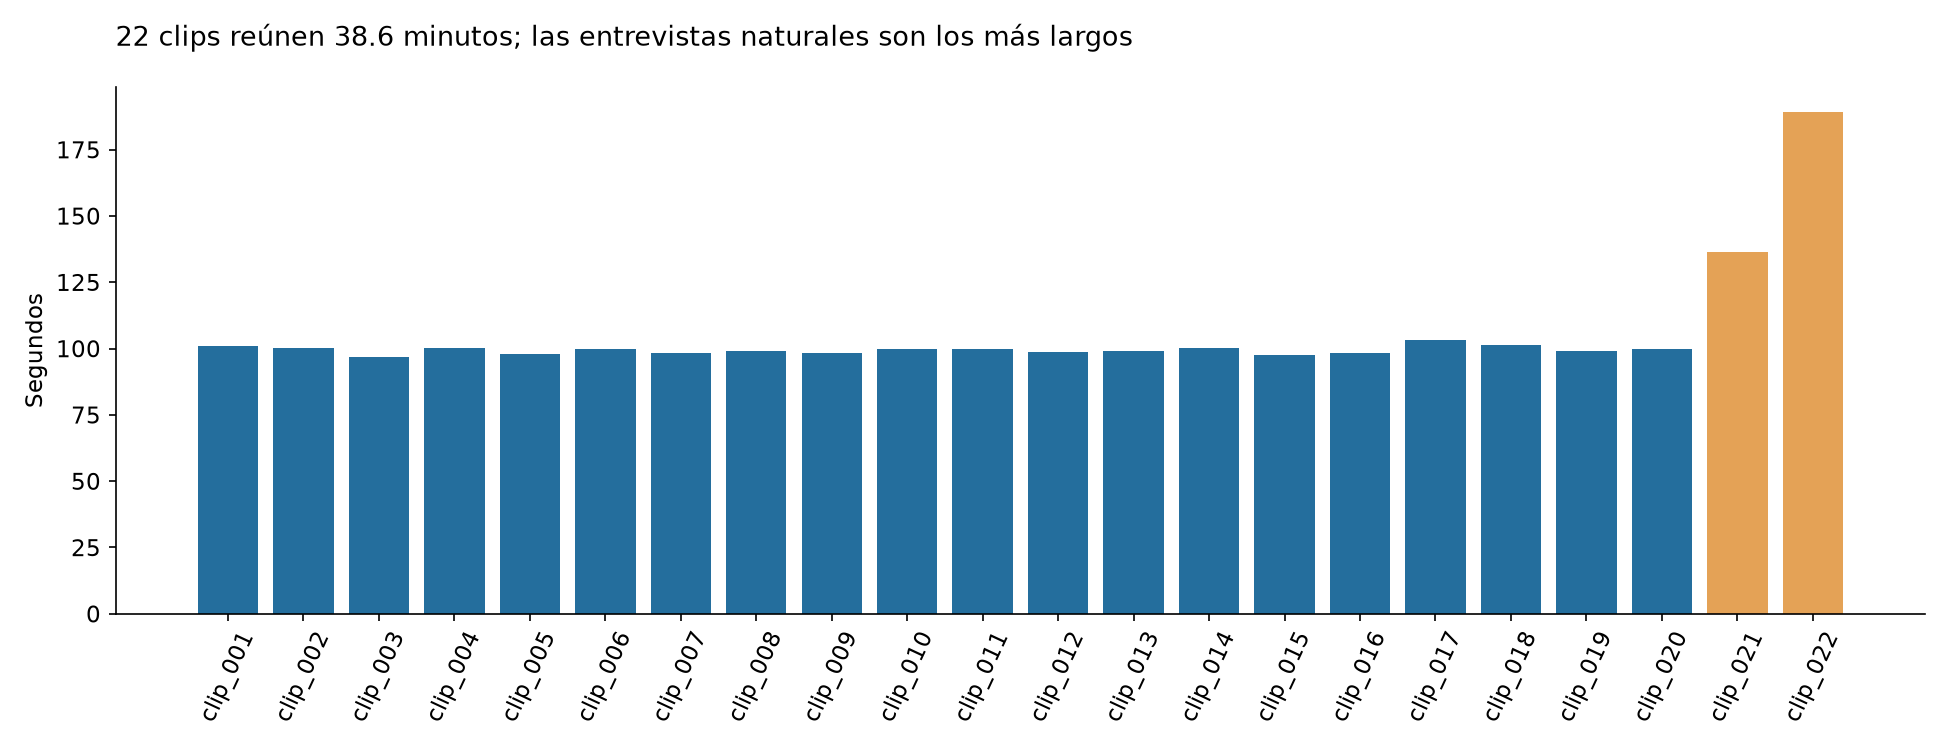

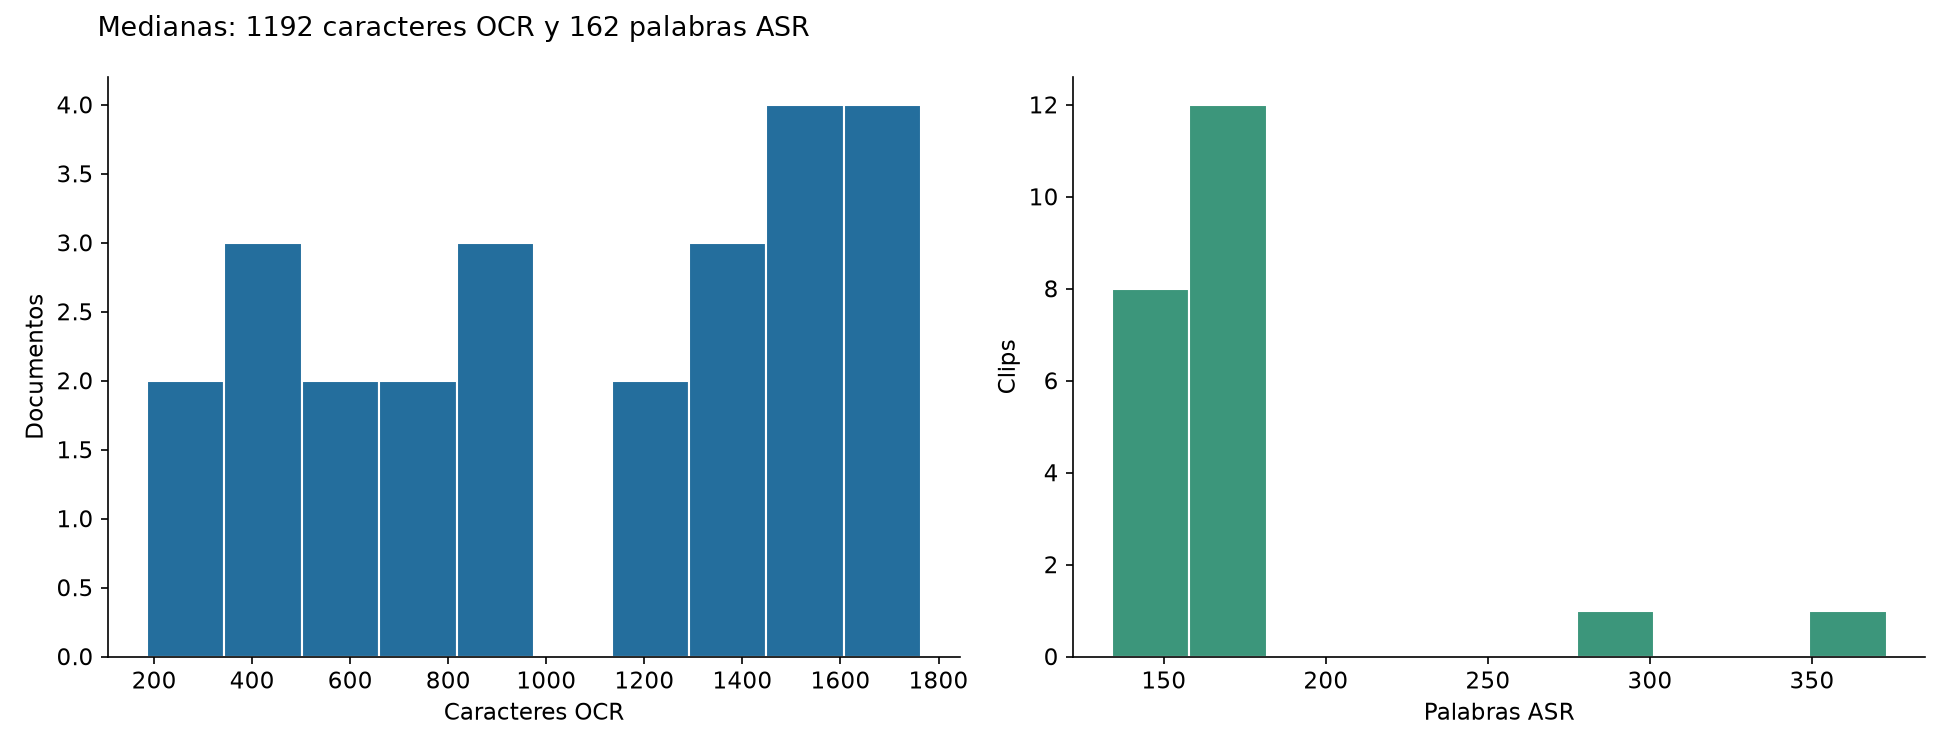

In [5]:
figuras = analisis_exploratorio()
for i, figura in enumerate(figuras, 1):
    figura.show()
    png = DATOS/'graficos'/f'eda_{i}.png'
    if png.exists(): display(Image(filename=str(png)))


## Hablantes y condiciones de audio

Los 20 montajes de OpenSLR no son entrevistas naturales y pueden contener muchas voces. Los identificadores de procedencia no equivalen a hablantes detectados. Las entrevistas callejeras añaden ruido y cambios espontáneos de turno. El agrupamiento puede fusionar voces o dividir una sola; el número detectado requiere contraste auditivo.

In [6]:
meta_audio = leer_csv(DATOS/'fuentes_audio.csv')
display(audios[['id','duracion_seg','n_hablantes','modelo_asr']])
display(meta_audio[['id','fuente_url','procedencia','n_voces_fuente']])
print('Corpus final extraído:', len(documentos), 'documentos y', len(audios), 'clips.')
print('Verificar antes de entregar: privacidad vigente, evidencias auténticas y enlace público funcional.')


,id,duracion_seg,n_hablantes,modelo_asr
0,clip_001,101.03,,faster-whisper small; CPU; int8; VAD
1,clip_002,100.19,,faster-whisper small; CPU; int8; VAD
2,clip_003,96.91,,faster-whisper small; CPU; int8; VAD
3,clip_004,100.27,,faster-whisper small; CPU; int8; VAD
4,clip_005,98.07,,faster-whisper small; CPU; int8; VAD
5,clip_006,99.76,,faster-whisper small; CPU; int8; VAD
6,clip_007,98.23,,faster-whisper small; CPU; int8; VAD
7,clip_008,98.91,,faster-whisper small; CPU; int8; VAD
8,clip_009,98.14,,faster-whisper small; CPU; int8; VAD
9,clip_010,99.68,,faster-whisper small; CPU; int8; VAD


,id,fuente_url,procedencia,n_voces_fuente
0,clip_001,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,12
1,clip_002,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,10
2,clip_003,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,10
3,clip_004,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,13
4,clip_005,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,9
5,clip_006,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,13
6,clip_007,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,11
7,clip_008,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,10
8,clip_009,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,10
9,clip_010,https://www.openslr.org/73/,Locuciones originales de OpenSLR 73 concatenad...,12


Corpus final extraído: 25 documentos y 22 clips.
Verificar antes de entregar: privacidad vigente, evidencias auténticas y enlace público funcional.
